## Breit Rabi Calculation

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%cd ..

c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


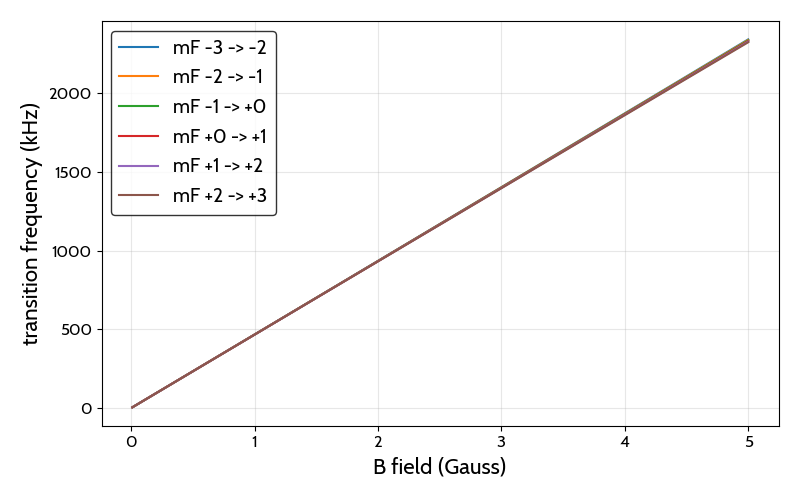

In [7]:
 
h    = 6.62607015e-34     # Planck's constant (J s)
mu_B = 9.2740100783e-24   # Bohr magneton (J/T)
 

I    = 2.5
dEhf = 3e9   # hyperfine splitting (Hz)
gJ   = 2.0023
gI   = -0.0002936
 
def breit_rabi(B, sign=+1):
    F  = I + sign * 0.5
    mF = np.arange(-F, F + 0.5, 1.0)
    x  = (gJ - gI) * mu_B * B / (h * dEhf)        
    E  = (gI * mu_B * B * mF) / h \
         + sign * (dEhf / 2) * np.sqrt(1 + (4 * mF / (2 * I + 1)) * x + x**2)  
    return mF, E
 
B_gauss = np.linspace(0.01, 5, 200)  
B_tesla = B_gauss * 1e-4
 
spacings_all = []
for B in B_tesla:
    mF, E = breit_rabi(B, sign=+1)
    spacings_all.append(np.diff(E))      
spacings_all = np.array(spacings_all) / 1e3   
 


fig, ax = plt.subplots(figsize=(8, 5), tight_layout=True)
 
n_trans = spacings_all.shape[1]
for i in range(n_trans):
    ax.plot(B_gauss, spacings_all[:, i], label=f"mF {i-3:+d} -> {i-2:+d}")
ax.set_ylabel("transition frequency (kHz)")
ax.set_xlabel("B field (Gauss)")
ax.legend()
ax.grid(True, alpha=0.3)
 

# fig.savefig("figures/breit_rabi.svg", format="svg")


In [5]:
%matplotlib ipympl